# Image Processing Using Python — Practical File 2

**Lab 9 assignment | Six problems**

This practical implements exactly the six problems in the Lab 9 assignment section: comparative edge detection, noise sensitivity, RLE versus Huffman compression, JPEG-style block artifacts, GLCM texture segmentation, and multi-feature plant-image segmentation.

The input images are bundled in `images/`. The outdoor scene is the locally bundled `scikit-image` sample image `rocket`; the document, cityscape, texture mosaic and plant image are synthetic educational examples. No external image download is required. The plant example is a visual segmentation demonstration, not medical diagnosis or validated disease detection.


## 1. Import libraries and validate image assets


In [4]:
%matplotlib inline
from pathlib import Path
import heapq
import itertools
import math
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity, mean_squared_error
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path.cwd()
if not (BASE_DIR / 'images').is_dir() and (BASE_DIR / 'Assignment_2_Practical_File_2' / 'images').is_dir():
    BASE_DIR = BASE_DIR / 'Assignment_2_Practical_File_2'
IMAGE_DIR = BASE_DIR / 'images'
required_files = ['outdoor_scene.png', 'noise_clean.png', 'document_scan.png', 'city_scene.png', 'texture_mosaic.png', 'synthetic_leaf_disease.png', 'synthetic_leaf_reference_mask.png', 'synthetic_spot_reference_mask.png']
missing = [name for name in required_files if not (IMAGE_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing image assets in {IMAGE_DIR}: {missing}')

def read_gray(name):
    path=IMAGE_DIR/name
    image=cv2.imread(str(path),cv2.IMREAD_GRAYSCALE)
    if image is None: raise FileNotFoundError(f'Could not read {path}')
    return image

def read_rgb(name):
    path=IMAGE_DIR/name
    image=cv2.imread(str(path),cv2.IMREAD_COLOR)
    if image is None: raise FileNotFoundError(f'Could not read {path}')
    return cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

print('Validated bundled assets:', len(required_files))
print('Image directory:', IMAGE_DIR.resolve())


Validated bundled assets: 8
Image directory: C:\Users\PC\OneDrive\Desktop\Image_Processing_Assignments\Assignment_2_Practical_File_2\images


## Problem 1 — Comparative Edge Detection on a Natural Outdoor Image

**Problem:** Apply Sobel, Laplacian and Canny edge detection to an outdoor natural image, compare their outputs, and explain which operator captures the most meaningful edges.

Sobel estimates first-order intensity gradients, Laplacian measures second-order intensity changes, and Canny combines smoothing, gradient estimation, non-maximum suppression and hysteresis thresholding.


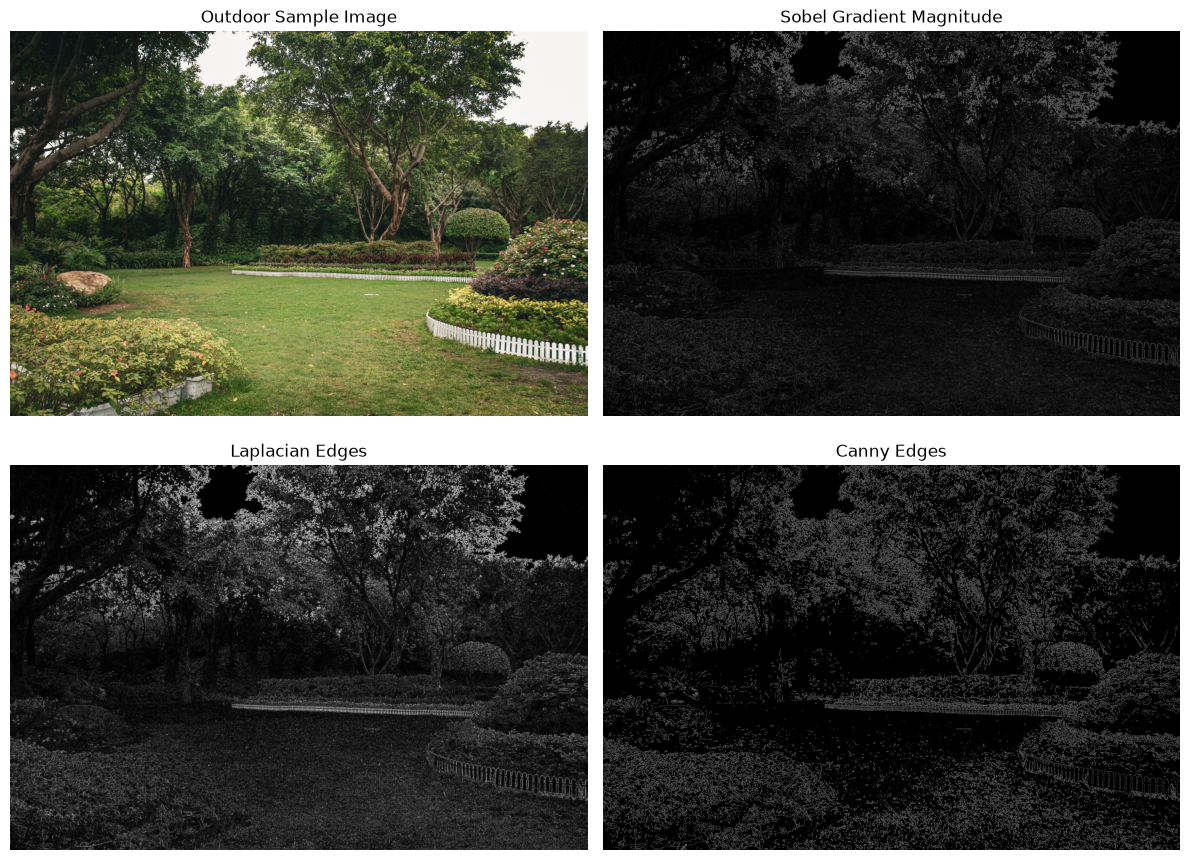

Edge maps generated. Canny edge pixels: 1137066 / 15991970


In [5]:
outdoor_rgb = read_rgb('outdoor_scene.png')
outdoor_gray = cv2.cvtColor(outdoor_rgb, cv2.COLOR_RGB2GRAY)

sobel_x = cv2.Sobel(outdoor_gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(outdoor_gray, cv2.CV_32F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_display = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
laplacian = cv2.Laplacian(outdoor_gray, cv2.CV_32F, ksize=3)
laplacian_display = cv2.convertScaleAbs(laplacian)
canny = cv2.Canny(cv2.GaussianBlur(outdoor_gray, (5,5), 1.0), 70, 150)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
views=[(outdoor_rgb,'Outdoor Sample Image'),(sobel_display,'Sobel Gradient Magnitude'),(laplacian_display,'Laplacian Edges'),(canny,'Canny Edges')]
for ax,(image,title) in zip(axes.ravel(),views):
    ax.imshow(image, cmap='gray' if image.ndim==2 else None); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem1_edge_comparison.png',dpi=150,bbox_inches='tight'); plt.show()
print('Edge maps generated. Canny edge pixels:', int(np.count_nonzero(canny)), '/', canny.size)


### Problem 1 — Analysis

Canny generally produces the clearest and most continuous structural outlines in this comparison because it smooths noise, suppresses non-maximum responses and links edges using two thresholds. Sobel is useful for showing gradient strength and direction, but often produces thicker responses and retains texture. The Laplacian responds to rapid intensity changes in all directions, including fine texture and noise, so it can look busy without smoothing. The best operator depends on the objective: Canny is often best for a clean edge map, while Sobel is valuable when gradient magnitude is itself needed.


## Problem 2 — Noise Sensitivity Experiment

**Problem:** Add Gaussian and salt-and-pepper noise to a clean grayscale image, apply Sobel and Laplacian to both noisy versions, and evaluate sensitivity, edge clarity and preprocessing.


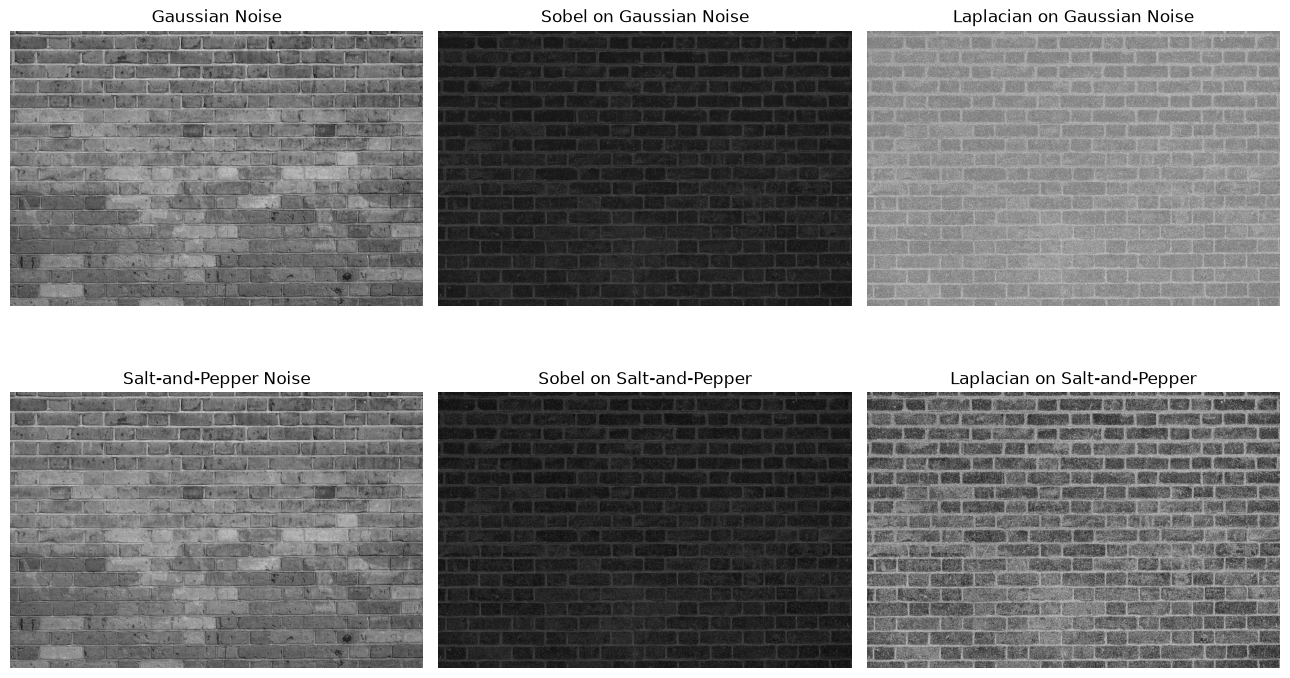

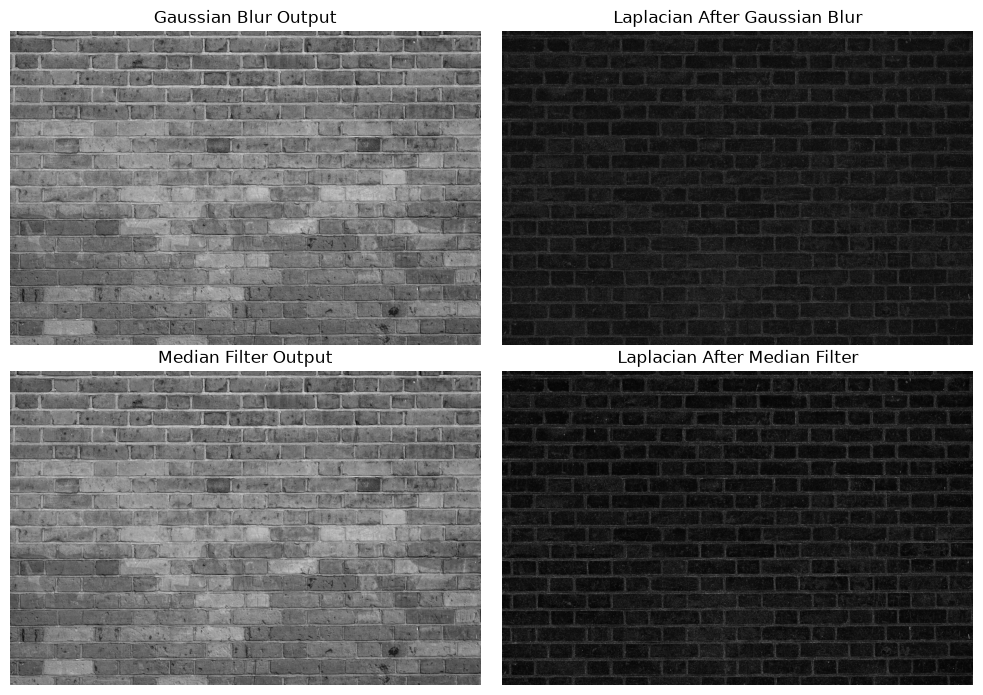

Noisy-image arrays: (4000, 6000) (4000, 6000)
Salt/pepper changed-pixel fraction: 0.036


In [6]:
clean = read_gray('noise_clean.png')
rng = np.random.default_rng(27)
gaussian_noise = rng.normal(0, 20, clean.shape)
gaussian_noisy = np.clip(clean.astype(np.float32) + gaussian_noise, 0, 255).astype(np.uint8)
salt_pepper_noisy = clean.copy()
noise_map = rng.random(clean.shape)
salt_pepper_noisy[noise_map < 0.018] = 0
salt_pepper_noisy[noise_map > 0.982] = 255

def sobel_laplacian_maps(image):
    gx=cv2.Sobel(image,cv2.CV_32F,1,0,ksize=3)
    gy=cv2.Sobel(image,cv2.CV_32F,0,1,ksize=3)
    sobel=cv2.normalize(cv2.magnitude(gx,gy),None,0,255,cv2.NORM_MINMAX).astype(np.uint8)
    lap=cv2.convertScaleAbs(cv2.Laplacian(image,cv2.CV_32F,ksize=3))
    return sobel,lap

sobel_gauss, lap_gauss = sobel_laplacian_maps(gaussian_noisy)
sobel_sp, lap_sp = sobel_laplacian_maps(salt_pepper_noisy)
fig,axes=plt.subplots(2,3,figsize=(13,8))
for ax,img,title in zip(axes[0],[gaussian_noisy,sobel_gauss,lap_gauss],['Gaussian Noise','Sobel on Gaussian Noise','Laplacian on Gaussian Noise']):
    ax.imshow(img,cmap='gray'); ax.set_title(title); ax.axis('off')
for ax,img,title in zip(axes[1],[salt_pepper_noisy,sobel_sp,lap_sp],['Salt-and-Pepper Noise','Sobel on Salt-and-Pepper','Laplacian on Salt-and-Pepper']):
    ax.imshow(img,cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem2_noise_sensitivity.png',dpi=150,bbox_inches='tight'); plt.show()

# Preprocessing demonstration: Gaussian blur for Gaussian noise; median filter for impulse noise.
gaussian_denoised=cv2.GaussianBlur(gaussian_noisy,(5,5),1.2)
sp_denoised=cv2.medianBlur(salt_pepper_noisy,5)
_,lap_gauss_denoised=sobel_laplacian_maps(gaussian_denoised)
_,lap_sp_denoised=sobel_laplacian_maps(sp_denoised)
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,img,title in zip(axes.ravel(),[gaussian_denoised,lap_gauss_denoised,sp_denoised,lap_sp_denoised],['Gaussian Blur Output','Laplacian After Gaussian Blur','Median Filter Output','Laplacian After Median Filter']):
    ax.imshow(img,cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem2_denoising_comparison.png',dpi=150,bbox_inches='tight'); plt.show()
print('Noisy-image arrays:', gaussian_noisy.shape, salt_pepper_noisy.shape)
print('Salt/pepper changed-pixel fraction:', round(float(np.mean(noise_map < 0.018) + np.mean(noise_map > 0.982)),4))


### Problem 2 — Analysis

The Laplacian is usually more affected by noise because a second derivative gives a strong response to small, rapid pixel fluctuations. Sobel also responds to noise, but its first-derivative filters are generally less noise-amplifying. Gaussian noise adds fine variations across many pixels; salt-and-pepper noise creates extreme isolated values that generate strong false edges and reduce edge-map clarity. A Gaussian blur is a suitable first step for Gaussian noise, while a median filter is particularly effective for salt-and-pepper noise. Preprocessing improves edge continuity, although excessive smoothing can remove genuine fine detail.


## Problem 3 — Compression Ratio Comparison: Run-Length Encoding vs Huffman Coding

**Problem:** Compress a grayscale image with large smooth regions using RLE and Huffman coding. Calculate the original bit length, compressed bit length and percentage reduction; then compare the methods.

**Accounting assumptions:** the original grayscale payload uses 8 bits per pixel. RLE stores each run as an 8-bit pixel value plus a fixed-width run count large enough for the image, with a 32-bit pixel-count header. Huffman stores the encoded payload plus a compact codebook representation of 16 bits per used symbol (8-bit symbol + 8-bit code length) and the same 32-bit pixel-count header. These are theoretical bit counts, not actual filesystem sizes; Python list/object overhead and byte/container metadata are excluded.


Image size: 3419 x 5128 = 17,532,632 pixels
Original size: 140,261,056 bits
RLE: 8,978,022 runs | 296,274,758 bits | ratio 0.473:1 | reduction -111.23%
Huffman: 254 symbols | payload 123,298,884 bits + header 4,096 bits = 123,302,980 bits | ratio 1.138:1 | reduction 12.09%
RLE reconstruction exact: True


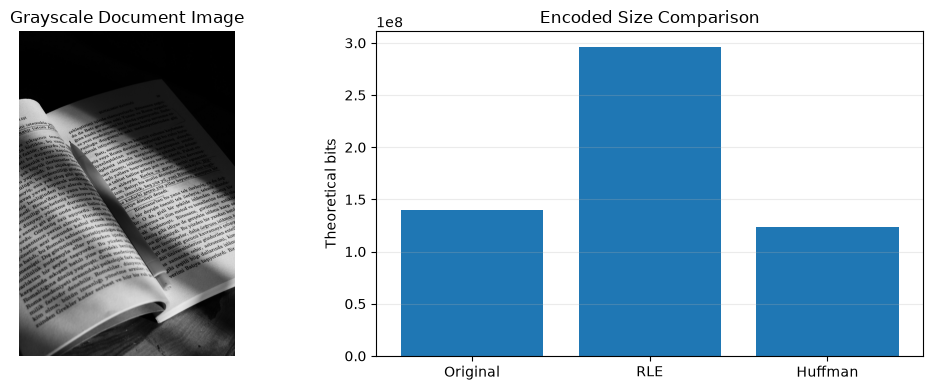

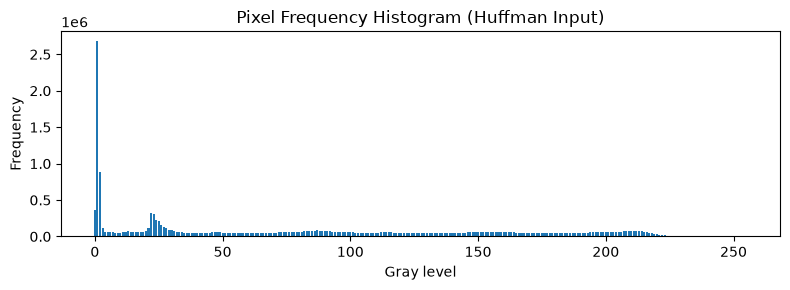

In [7]:
document = read_gray('document_scan.png')
flat = document.ravel()
pixel_count = int(flat.size)
original_bits = pixel_count * 8

def rle_encode(values):
    values=np.asarray(values).ravel()
    if values.size==0: return []
    runs=[]; current=int(values[0]); length=1
    for value in values[1:]:
        value=int(value)
        if value==current: length+=1
        else: runs.append((current,length)); current=value; length=1
    runs.append((current,length))
    return runs

def rle_decode(runs):
    return np.concatenate([np.full(length,value,dtype=np.uint8) for value,length in runs])

runs=rle_encode(flat)
count_bits=math.ceil(math.log2(pixel_count+1))
rle_bits=len(runs)*(8+count_bits)+32
rle_reconstructed=rle_decode(runs).reshape(document.shape)
assert np.array_equal(document,rle_reconstructed)

# Build a Huffman tree using a deterministic tie-break counter.
def build_huffman_codes(values):
    vals=np.asarray(values).ravel()
    symbols,counts=np.unique(vals,return_counts=True)
    counter=itertools.count()
    heap=[(int(count),next(counter),('leaf',int(symbol))) for symbol,count in zip(symbols,counts)]
    heapq.heapify(heap)
    if len(heap)==1:
        return {int(symbols[0]):'0'}, {int(symbols[0]):int(counts[0])}
    while len(heap)>1:
        f1,_,n1=heapq.heappop(heap); f2,_,n2=heapq.heappop(heap)
        heapq.heappush(heap,(f1+f2,next(counter),('node',n1,n2)))
    root=heap[0][2]; codes={}
    def walk(node,prefix):
        if node[0]=='leaf': codes[node[1]]=prefix or '0'
        else:
            walk(node[1],prefix+'0'); walk(node[2],prefix+'1')
    walk(root,'')
    return codes,{int(s):int(c) for s,c in zip(symbols,counts)}

huffman_codes,frequencies=build_huffman_codes(flat)
huffman_payload_bits=sum(frequencies[symbol]*len(codeword) for symbol,codeword in huffman_codes.items())
huffman_header_bits=len(huffman_codes)*16+32
huffman_bits=huffman_payload_bits+huffman_header_bits

def compression_stats(encoded_bits):
    reduction=(1-encoded_bits/original_bits)*100
    ratio=original_bits/encoded_bits
    return ratio,reduction

rle_ratio,rle_reduction=compression_stats(rle_bits)
huff_ratio,huff_reduction=compression_stats(huffman_bits)
print(f'Image size: {document.shape[1]} x {document.shape[0]} = {pixel_count:,} pixels')
print(f'Original size: {original_bits:,} bits')
print(f'RLE: {len(runs):,} runs | {rle_bits:,} bits | ratio {rle_ratio:.3f}:1 | reduction {rle_reduction:.2f}%')
print(f'Huffman: {len(huffman_codes):,} symbols | payload {huffman_payload_bits:,} bits + header {huffman_header_bits:,} bits = {huffman_bits:,} bits | ratio {huff_ratio:.3f}:1 | reduction {huff_reduction:.2f}%')
print('RLE reconstruction exact:', bool(np.array_equal(document,rle_reconstructed)))

fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].imshow(document,cmap='gray'); axes[0].set_title('Grayscale Document Image'); axes[0].axis('off')
axes[1].bar(['Original','RLE','Huffman'],[original_bits,rle_bits,huffman_bits]); axes[1].set_ylabel('Theoretical bits'); axes[1].set_title('Encoded Size Comparison'); axes[1].grid(axis='y',alpha=.25)
plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem3_compression_sizes.png',dpi=150,bbox_inches='tight'); plt.show()
plt.figure(figsize=(8,3)); plt.bar(list(frequencies.keys()),list(frequencies.values())); plt.title('Pixel Frequency Histogram (Huffman Input)'); plt.xlabel('Gray level'); plt.ylabel('Frequency'); plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem3_pixel_histogram.png',dpi=150,bbox_inches='tight'); plt.show()


### Problem 3 — Analysis

RLE is effective when adjacent pixels repeat for long runs, as in large smooth backgrounds and document-like images. It can become inefficient on noisy or highly textured images because short runs require repeated value/count records. Huffman coding uses shorter codes for frequent pixel values and is therefore driven by the overall symbol-frequency distribution rather than spatial adjacency. In this example, both methods are measured with their stated header assumptions; the better result is the one with the smaller encoded bit count, not necessarily the one with the simpler algorithm. The values above represent theoretical bitstream accounting rather than a compressed image file written by a production codec.


## Problem 4 — JPEG-Style 8 × 8 DCT Compression and Block Artifact Analysis

**Problem:** Convert a colour city image to YCrCb, process 8 × 8 blocks with DCT and JPEG-style quantisation, reconstruct at low, medium and high quantisation levels, and compare MSE, PSNR and SSIM.

The standard luminance quantisation matrix is applied to each YCrCb channel as a simplified educational JPEG-style pipeline. Low quantisation uses a smaller matrix multiplier (less information loss); high quantisation uses a larger multiplier (more information loss). This is not a complete JPEG encoder: entropy coding, chroma subsampling, file headers and bitstream packaging are not included.


Low quantisation: MSE=3.608 | PSNR=42.558 dB | SSIM=0.98786
Medium quantisation: MSE=12.075 | PSNR=37.312 dB | SSIM=0.93409
High quantisation: MSE=25.254 | PSNR=34.107 dB | SSIM=0.90700


C:\Users\PC\AppData\Local\Temp\ipykernel_5008\1915702666.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem4_jpeg_artifact_comparison.png',dpi=150,bbox_inches='tight'); plt.show()


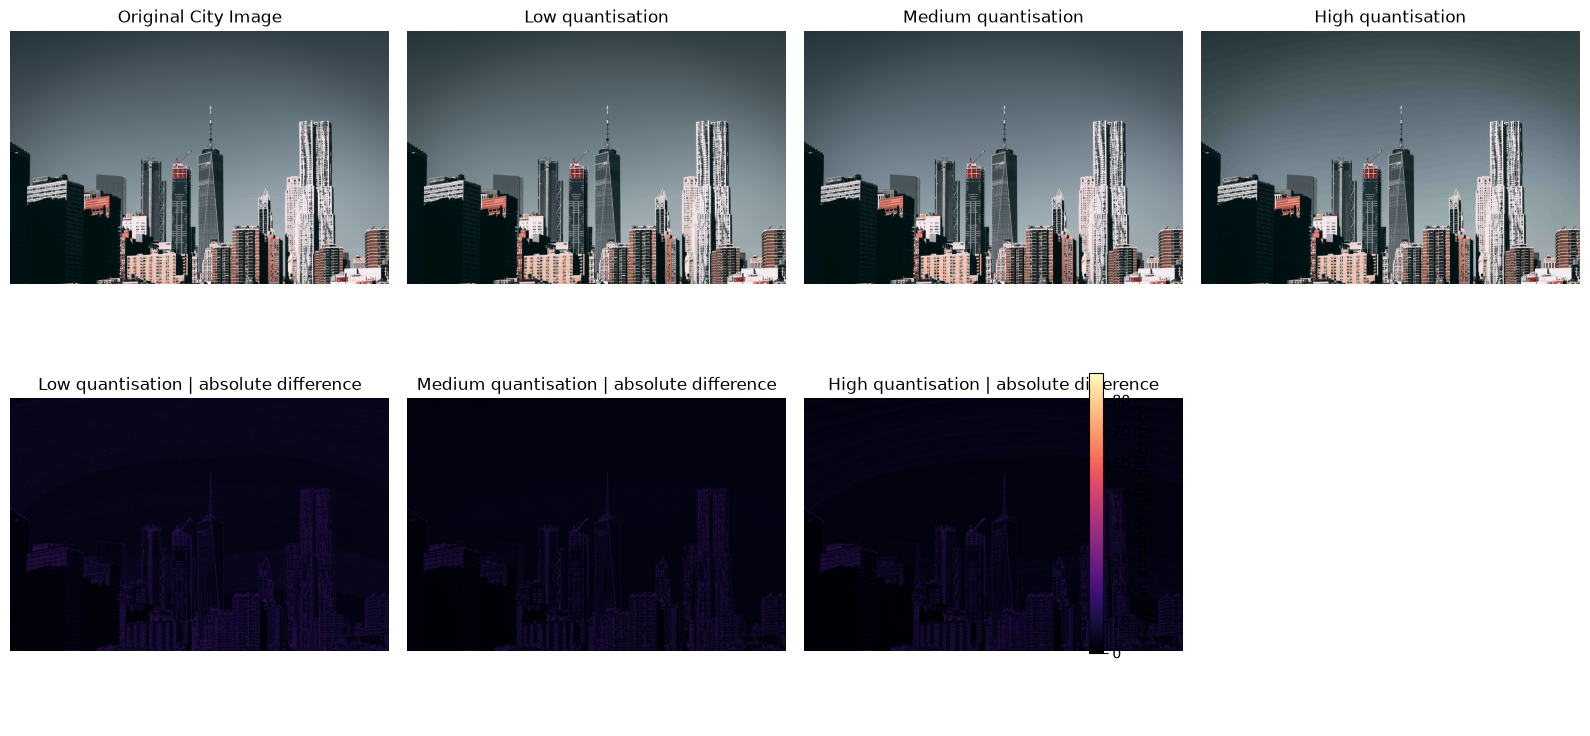

In [8]:
city_rgb=read_rgb('city_scene.png')
Q=np.array([[16,11,10,16,24,40,51,61],
            [12,12,14,19,26,58,60,55],
            [14,13,16,24,40,57,69,56],
            [14,17,22,29,51,87,80,62],
            [18,22,37,56,68,109,103,77],
            [24,35,55,64,81,104,113,92],
            [49,64,78,87,103,121,120,101],
            [72,92,95,98,112,100,103,99]],dtype=np.float32)

def jpeg_style_reconstruct(rgb, quant_multiplier):
    ycc=cv2.cvtColor(rgb,cv2.COLOR_RGB2YCrCb).astype(np.float32)
    h,w,ch=ycc.shape
    pad_h=(8-h%8)%8; pad_w=(8-w%8)%8
    padded=cv2.copyMakeBorder(ycc,0,pad_h,0,pad_w,cv2.BORDER_REFLECT)
    reconstructed=np.empty_like(padded)
    quant_matrix=Q*float(quant_multiplier)
    for channel in range(ch):
        for y0 in range(0,padded.shape[0],8):
            for x0 in range(0,padded.shape[1],8):
                block=padded[y0:y0+8,x0:x0+8,channel]-128.0
                coeff=cv2.dct(block)
                quantized=np.round(coeff/quant_matrix)*quant_matrix
                restored=cv2.idct(quantized)+128.0
                reconstructed[y0:y0+8,x0:x0+8,channel]=restored
    cropped=np.clip(reconstructed[:h,:w,:],0,255).astype(np.uint8)
    return cv2.cvtColor(cropped,cv2.COLOR_YCrCb2RGB)

quant_levels={'Low quantisation':0.55,'Medium quantisation':1.0,'High quantisation':2.2}
reconstructions={name:jpeg_style_reconstruct(city_rgb,mult) for name,mult in quant_levels.items()}
metrics=[]
for name,recon in reconstructions.items():
    mse=float(mean_squared_error(city_rgb,recon))
    psnr=float(peak_signal_noise_ratio(city_rgb,recon,data_range=255))
    ssim=float(structural_similarity(city_rgb,recon,channel_axis=-1,data_range=255))
    metrics.append((name,mse,psnr,ssim))
    print(f'{name}: MSE={mse:.3f} | PSNR={psnr:.3f} dB | SSIM={ssim:.5f}')
    Image.fromarray(recon).save(IMAGE_DIR/(name.lower().replace(' ','_')+'.png'))

fig,axes=plt.subplots(2,4,figsize=(16,8))
axes[0,0].imshow(city_rgb); axes[0,0].set_title('Original City Image'); axes[0,0].axis('off')
for ax,(name,recon) in zip(axes[0,1:],reconstructions.items()):
    ax.imshow(recon); ax.set_title(name); ax.axis('off')
for ax,(name,recon) in zip(axes[1,:3],reconstructions.items()):
    diff=np.mean(np.abs(city_rgb.astype(np.float32)-recon.astype(np.float32)),axis=2)
    im=ax.imshow(diff,cmap='magma',vmin=0,vmax=max(1,float(diff.max())))
    ax.set_title(name+' | absolute difference'); ax.axis('off')
axes[1,3].axis('off')
fig.colorbar(im,ax=axes[1,:3],fraction=.025,pad=.02,label='Mean absolute RGB difference')
plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem4_jpeg_artifact_comparison.png',dpi=150,bbox_inches='tight'); plt.show()


### Problem 4 — Analysis

Increasing quantisation removes more high-frequency DCT coefficients, which reduces detail and can produce visible 8 × 8 block boundaries, ringing and loss of fine texture. Low quantisation normally retains more detail and gives higher PSNR/SSIM; high quantisation normally gives lower PSNR/SSIM and larger reconstruction error. PSNR reflects pixel-wise error, while SSIM compares local structural and contrast similarity. Small textured regions and sharp edges tend to show degradation more clearly than smooth areas.


## Problem 5 — Texture-Based Segmentation using GLCM Features (k = 3)

**Problem:** Extract local GLCM contrast, energy and homogeneity over image neighbourhoods, then segment a multi-texture image into three clusters.

The image is quantised to eight gray levels to keep each local co-occurrence matrix compact. Horizontal and vertical grey-level pairs are counted in a sliding 15 × 15 window centred at every pixel. The resulting per-pixel GLCM contrast, energy and homogeneity maps are then standardised and clustered.


Per-pixel GLCM feature array: (3043328, 3) | Cluster IDs: [0, 1, 2] | Number of clusters: 3


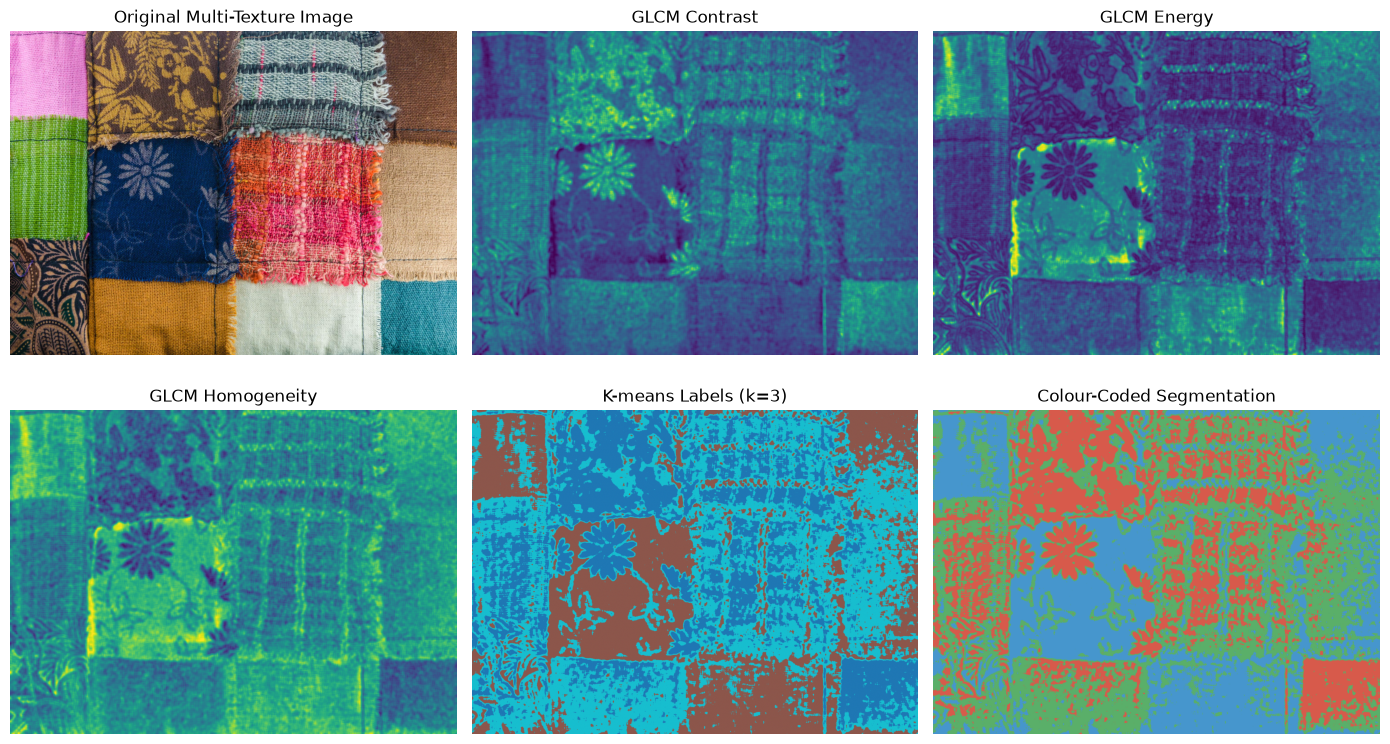

In [9]:
texture_rgb=read_rgb('texture_mosaic.png')
texture_gray=cv2.cvtColor(texture_rgb,cv2.COLOR_RGB2GRAY)
levels=8
quantized=(texture_gray//32).astype(np.uint8)
window_size=15
h,w=quantized.shape

# Build local GLCM pair counts at every pixel neighbourhood.
# Horizontal and vertical neighbour pairs are counted in a 15 x 15 window.
pair_counts=np.zeros((h,w,levels*levels),dtype=np.float32)
for direction in ['horizontal','vertical']:
    pair_index=np.zeros((h,w),dtype=np.uint8)
    valid=np.zeros((h,w),dtype=np.uint8)
    if direction=='horizontal':
        pair_index[:,:-1]=quantized[:,:-1]*levels+quantized[:,1:]
        valid[:,:-1]=1
    else:
        pair_index[:-1,:]=quantized[:-1,:]*levels+quantized[1:,:]
        valid[:-1,:]=1
    for pair_code in range(levels*levels):
        pair_mask=((pair_index==pair_code)&(valid>0)).astype(np.float32)
        pair_counts[:,:,pair_code]+=cv2.boxFilter(
            pair_mask,ddepth=-1,ksize=(window_size,window_size),
            normalize=False,borderType=cv2.BORDER_REFLECT
        )

# Normalize each local co-occurrence matrix and calculate standard GLCM properties.
probabilities=pair_counts/(pair_counts.sum(axis=2,keepdims=True)+1e-8)
gray_i=np.repeat(np.arange(levels),levels)
gray_j=np.tile(np.arange(levels),levels)
difference=(gray_i-gray_j).astype(np.float32)
contrast_weights=difference**2
homogeneity_weights=1.0/(1.0+contrast_weights)
contrast_map=np.tensordot(probabilities,contrast_weights,axes=([2],[0]))
energy_map=np.sqrt(np.sum(probabilities**2,axis=2))
homogeneity_map=np.tensordot(probabilities,homogeneity_weights,axes=([2],[0]))

# One three-feature vector is now available for every pixel.
features=np.column_stack([contrast_map.ravel(),energy_map.ravel(),homogeneity_map.ravel()])
features_scaled=StandardScaler().fit_transform(features)
kmeans_texture=KMeans(n_clusters=3,random_state=42,n_init=10,max_iter=150)
labels_full=kmeans_texture.fit_predict(features_scaled).reshape(h,w)
cluster_ids=np.unique(labels_full)
if len(cluster_ids)!=3:
    raise RuntimeError(f'Expected exactly 3 texture clusters; found {len(cluster_ids)}')
cluster_palette=np.array([[215,90,75],[70,150,205],[90,175,105]],dtype=np.uint8)
segmented_texture=cluster_palette[labels_full]
print('Per-pixel GLCM feature array:',features.shape,'| Cluster IDs:',cluster_ids.tolist(),'| Number of clusters:',len(cluster_ids))

fig,axes=plt.subplots(2,3,figsize=(14,8))
plots=[(texture_rgb,'Original Multi-Texture Image',None),(contrast_map,'GLCM Contrast','viridis'),(energy_map,'GLCM Energy','viridis'),(homogeneity_map,'GLCM Homogeneity','viridis'),(labels_full,'K-means Labels (k=3)','tab10'),(segmented_texture,'Colour-Coded Segmentation',None)]
for ax,(image,title,cmap) in zip(axes.ravel(),plots):
    ax.imshow(image,cmap=cmap); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.savefig(IMAGE_DIR/'problem5_glcm_texture_segmentation.png',dpi=150,bbox_inches='tight'); plt.show()


### Problem 5 — Observations

GLCM contrast responds to local gray-level changes and can separate strongly patterned areas from smoother ones. Energy is higher when co-occurrences are concentrated in a smaller number of gray-level pairs; homogeneity is higher when neighbouring gray levels are similar. Combining the three features gives K-means information about local texture that raw intensity alone would not provide. The cluster labels are arbitrary identifiers, not semantic class names. Segmentation quality depends on neighbourhood size, gray-level quantisation, feature scaling and the visual distinctiveness of the textures.


## Problem 6 — Multi-Feature Segmentation for Plant Disease-Like Regions

**Problem:** Combine intensity, Sobel gradient magnitude and local 3 × 3 texture variance; segment the image with K-means; display the image, feature maps and segmented output.

The bundled plant image is synthetic and contains simulated brown spot-like regions. Its reference masks are used only to compare the image features in this generated example. They are not medical or botanical ground truth and cannot establish real disease-detection accuracy.


K-means cluster IDs: [0, 1, 2] | Cluster count: 3


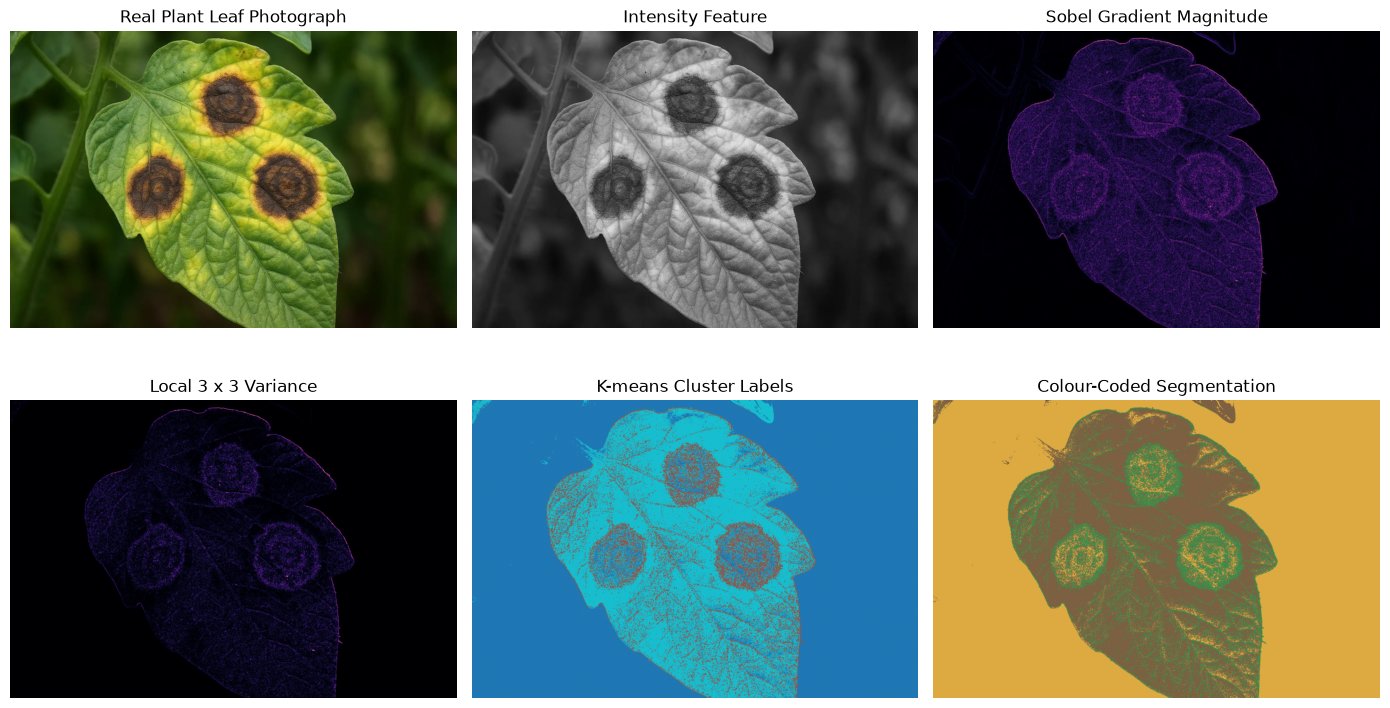


K-means Cluster Composition — Real Photograph

Cluster 0: 954,542 pixels (60.69%)
  Intensity: 0.1688
  Sobel Gradient: 0.0090
  Local Texture Variance: 0.0016

Cluster 1: 147,401 pixels (9.37%)
  Intensity: 0.4130
  Sobel Gradient: 0.2373
  Local Texture Variance: 0.1201

Cluster 2: 470,921 pixels (29.94%)
  Intensity: 0.5365
  Sobel Gradient: 0.1019
  Local Texture Variance: 0.0381

Total pixels analysed: 1572864
Total clusters: 3

Note: Clusters represent mathematical similarity in image features. They are not independently verified healthy or diseased biological labels.


In [12]:

# PROBLEM 6 — MULTI-FEATURE PLANT DISEASE SEGMENTATION

# 1. Load the real plant photograph
leaf_rgb = read_rgb('synthetic_leaf_disease.png')
leaf_gray = cv2.cvtColor(leaf_rgb, cv2.COLOR_RGB2GRAY)

# 2. Extract intensity feature
intensity = leaf_gray.astype(np.float32) / 255.0

# 3. Extract Sobel gradient magnitude
gx = cv2.Sobel(leaf_gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(leaf_gray, cv2.CV_32F, 0, 1, ksize=3)

gradient = cv2.magnitude(gx, gy)
gradient = gradient / (float(gradient.max()) + 1e-8)

# 4. Extract local texture variance
local_mean = cv2.blur(intensity, (3, 3))
local_mean_sq = cv2.blur(intensity**2, (3, 3))

local_variance = np.maximum(
    local_mean_sq - local_mean**2, 0.0
)

local_variance = local_variance / (
    float(local_variance.max()) + 1e-8
)

# 5. Combine all three features
feature_stack = np.dstack([
    intensity,
    gradient,
    local_variance
])

X_features = feature_stack.reshape(-1, 3)
X_scaled = StandardScaler().fit_transform(X_features)

# 6. Apply K-means clustering
kmeans_leaf = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
    max_iter=150
)

leaf_labels = kmeans_leaf.fit_predict(
    X_scaled
).reshape(leaf_gray.shape)

leaf_cluster_ids = np.unique(leaf_labels)

if len(leaf_cluster_ids) != 3:
    raise RuntimeError(
        f'Expected 3 clusters; found {len(leaf_cluster_ids)}'
    )

leaf_palette = np.array([
    [220, 170, 65],
    [55, 145, 75],
    [125, 95, 65]
], dtype=np.uint8)

leaf_segmented = leaf_palette[leaf_labels]

print(
    'K-means cluster IDs:',
    leaf_cluster_ids.tolist(),
    '| Cluster count:',
    len(leaf_cluster_ids)
)

# 7. Visualise all processing stages
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

views = [
    (leaf_rgb, 'Real Plant Leaf Photograph', None),
    (intensity, 'Intensity Feature', 'gray'),
    (gradient, 'Sobel Gradient Magnitude', 'magma'),
    (local_variance, 'Local 3 x 3 Variance', 'magma'),
    (leaf_labels, 'K-means Cluster Labels', 'tab10'),
    (leaf_segmented, 'Colour-Coded Segmentation', None)
]

for ax, (image, title, cmap) in zip(axes.ravel(), views):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / 'problem6_multifeature_plant_segmentation.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# 8. Analyse actual cluster composition
print('\nK-means Cluster Composition — Real Photograph')
print('=' * 55)

total_pixels = leaf_labels.size

for cluster_id in leaf_cluster_ids:

    cluster_mask = (leaf_labels == cluster_id)

    pixel_count = int(np.sum(cluster_mask))

    percentage = (
        pixel_count / total_pixels
    ) * 100

    print(
        f'\nCluster {cluster_id}: '
        f'{pixel_count:,} pixels ({percentage:.2f}%)'
    )

    # Calculate average value of each feature
    feature_names = [
        'Intensity',
        'Sobel Gradient',
        'Local Texture Variance'
    ]

    for idx, name in enumerate(feature_names):

        feature_values = feature_stack[:, :, idx][cluster_mask]

        print(
            f'  {name}: '
            f'{float(np.mean(feature_values)):.4f}'
        )

print('\n' + '=' * 55)
print('Total pixels analysed:', total_pixels)
print('Total clusters:', len(leaf_cluster_ids))

print(
    '\nNote: Clusters represent mathematical similarity '
    'in image features. They are not independently verified '
    'healthy or diseased biological labels.'
)


In [11]:
print("Leaf labels shape:", leaf_labels.shape)
print("Leaf mask shape:", leaf_mask.shape)
print("Spot mask shape:", spot_mask.shape)

print("Leaf labels size:", leaf_labels.size)
print("Leaf mask size:", leaf_mask.size)
print("Spot mask size:", spot_mask.size)

Leaf labels shape: (1024, 1536)
Leaf mask shape: (256, 320)
Spot mask shape: (256, 320)
Leaf labels size: 1572864
Leaf mask size: 81920
Spot mask size: 81920


### Problem 6 — Interpretation and limitations

Intensity can help separate darker brown spot-like regions from green leaf tissue. Local variance can add evidence when damaged-looking areas have irregular texture, while gradient magnitude is useful for boundaries and veins but may also respond strongly to healthy leaf edges. The printed standardised mean differences compare these features on the synthetic masks; the highest value indicates the strongest average contrast in this particular generated example.

The cluster-composition output also makes the limitation visible: small spot-like regions may be assigned to the same K-means cluster as most healthy leaf pixels. Potential misclassifications include dark healthy veins being grouped with brown spots, bright or yellow-green tissue being grouped separately, and boundary pixels mixing leaf and background. K-means is unsupervised and does not know which cluster is diseased; feature scaling, the number of clusters and image lighting affect the result. A real disease-detection system would require representative labelled field images, independent validation and domain-expert review. This synthetic demonstration is not a clinical or agricultural diagnostic model.


## Overall Conclusion

The six Lab 9 assignment problems have been implemented: Sobel/Laplacian/Canny comparison; Gaussian and impulse-noise sensitivity; bit-accounted RLE and Huffman comparison; block DCT/quantisation with MSE, PSNR and SSIM; local GLCM texture features with k=3 K-means; and three-feature K-means segmentation. Each problem includes executable code, plots and interpretation.
